# INF-PROF — Final project: exploring Chicago crime data with pandas

**Data:** `Chicago_Cimes_2008_to_2011.csv` — incidents reported to the Chicago Police Department, 2008–2011.

> Throughout this notebook, every number describes **recorded incidents in this dataset**, not the true incidence of crime.
> Not every crime gets reported, and the file itself turns out to be a subset of all the city's records (see Section 4).

**Structure**

- Part 1 — Data preparation and core questions (Sections 1–7)
- Part 2 — Open exploratory analysis of **BURGLARY** (Section 8)

The notebook runs from top to bottom. The CSV must sit in the same folder as the notebook.

## Setup

In [1]:
# Uncomment if a package is missing:
# %pip install pandas numpy matplotlib

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Relative path: the CSV is expected in the same directory as this notebook
DATA_PATH = Path("Chicago_Cimes_2008_to_2011.csv")

print("pandas", pd.__version__)

pandas 2.3.3


# Part 1 - Data preparation and core questions

## 1. Import dataset & Inspect

The first column of the file has no name (an index column left over from an earlier export). pandas calls it `Unnamed: 0`.

`ID` is read as **text** (`dtype={"ID": str}`) on purpose: Section 3 shows that one row holds a non-numeric value.
Reading the column as text lets us find that row ourselves, instead of letting pandas silently infer a mixed type.
`low_memory=False` makes pandas read the whole file before choosing the column types, which avoids a `DtypeWarning`.

In [3]:
raw_df = pd.read_csv(DATA_PATH, dtype={"ID": str}, low_memory=False)

**Display the first 5 rows of the DataFrame**

In [4]:
raw_df.head()

,Unnamed: 0,ID,Case.Number,Date,Block,IUCR,Primary.Type,Description,Location.Description,Arrest,...,Ward,Community.Area,FBI.Code,X.Coordinate,Y.Coordinate,Year,Updated.On,Latitude,Longitude,Location
0,1614394,6744641,HR162637,02/09/2009 03:50:00 PM,007XX S WELLS ST,2825,OTHER OFFENSE,HARASSMENT BY TELEPHONE,APARTMENT,False,...,2.0,32.0,26,1174826.0,1897096.0,2009.0,02/04/2016 06:33:39 AM,41.873022,-87.633595,"(41.873021973, -87.633594919)"
1,238567,6380338,HP465037,07/21/2008 11:30:00 PM,043XX S ROCKWELL ST,0610,BURGLARY,FORCIBLE ENTRY,APARTMENT,False,...,12.0,58.0,05,1159757.0,1875793.0,2008.0,02/04/2016 06:33:39 AM,41.814888,-87.689507,"(41.814887983, -87.689506618)"
2,2397513,7981904,HT214218,03/21/2011 07:00:00 PM,109XX S AVENUE G,1320,CRIMINAL DAMAGE,TO VEHICLE,STREET,False,...,10.0,52.0,14,1203188.0,1833070.0,2011.0,02/04/2016 06:33:39 AM,41.696650,-87.531659,"(41.696650294, -87.531658989)"
3,957963,7522917,HS326336,05/25/2010 08:35:00 PM,0000X S LAVERGNE AVE,2024,NARCOTICS,POSS: HEROIN(WHITE),SIDEWALK,True,...,28.0,25.0,18,1143268.0,1899434.0,2010.0,02/04/2016 06:33:39 AM,41.880085,-87.749402,"(41.880085253, -87.74940173)"
4,1909918,7216247,HR631679,11/07/2009 06:02:00 PM,085XX S WALLACE ST,0460,BATTERY,SIMPLE,CHA APARTMENT,False,...,21.0,71.0,08B,1173797.0,1848136.0,2009.0,02/04/2016 06:33:39 AM,41.738694,-87.638825,"(41.738693844, -87.638825362)"


**Display the last 5 rows of the DataFrame**

In [5]:
raw_df.tail()

,Unnamed: 0,ID,Case.Number,Date,Block,IUCR,Primary.Type,Description,Location.Description,Arrest,...,Ward,Community.Area,FBI.Code,X.Coordinate,Y.Coordinate,Year,Updated.On,Latitude,Longitude,Location
268866,2605355,8303648,HT538183,10/11/2011 03:09:00 PM,062XX S DORCHESTER AVE,2820,OTHER OFFENSE,TELEPHONE THREAT,RESIDENCE,False,...,20.0,42.0,26,1186608.0,1864035.0,2011.0,02/04/2016 06:33:39 AM,41.782029,-87.591387,"(41.782028888, -87.591386599)"
268867,141977,6226734,HP314115,05/03/2008 12:10:43 AM,110XX S SPAULDING AVE,0460,BATTERY,SIMPLE,BAR OR TAVERN,True,...,19.0,74.0,08B,1156297.0,1831142.0,2008.0,02/04/2016 06:33:39 AM,41.692429,-87.703398,"(41.692428934, -87.703397693)"
268868,1836515,7104315,HR513428,08/31/2009 08:19:00 PM,065XX S MARSHFIELD AVE,0470,PUBLIC PEACE VIOLATION,RECKLESS CONDUCT,VEHICLE NON-COMMERCIAL,False,...,15.0,67.0,24,1166451.0,1861338.0,2009.0,02/04/2016 06:33:39 AM,41.775081,-87.665364,"(41.775081483, -87.665364048)"
268869,1744173,6963964,HR356489,06/03/2009 03:00:00 PM,118XX S STEWART AVE,0330,ROBBERY,AGGRAVATED,SIDEWALK,False,...,34.0,53.0,03,1175755.0,1826400.0,2009.0,02/04/2016 06:33:39 AM,41.679004,-87.632300,"(41.679003591, -87.632300011)"
268870,857677,7366491,HS169090,02/16/2010 11:00:00 AM,015XX N AVERS AVE,2825,OTHER OFFENSE,HARASSMENT BY TELEPHONE,RESIDENCE,False,...,30.0,23.0,26,1150427.0,1909896.0,2010.0,02/04/2016 06:33:39 AM,41.908657,-87.722841,"(41.908657387, -87.722841164)"


In [6]:
n_rows, n_cols = raw_df.shape
print(f"Number of rows   : {n_rows:,}")
print(f"Number of columns: {n_cols}")

Number of rows   : 268,871
Number of columns: 23


**Column names & data types**

In [7]:
raw_df.dtypes.to_frame("dtype")

,dtype
Unnamed: 0,int64
ID,object
Case.Number,object
Date,object
Block,object
IUCR,object
Primary.Type,object
Description,object
Location.Description,object
Arrest,object


**Note:**
- `Arrest` and `Domestic` should be True/False, but pandas reads them as text.
- `Year`, `District` and `Ward` should be whole numbers, but pandas reads them as decimals (`float64`). `Community.Area` is even read as text.

All of this is caused by one broken row. We fix it in Section 3.

In [8]:
# Missing values: count and proportion, only for columns that have at least one
missing = pd.DataFrame({
    "number_missing": raw_df.isna().sum(),
    "prop_missing": raw_df.isna().mean(),
})
missing = missing[missing["number_missing"] > 0].sort_values("number_missing", ascending=False)
missing.round({"prop_missing": 4})

,number_missing,prop_missing
Location,2890,0.0107
Latitude,2890,0.0107
Longitude,2890,0.0107
Y.Coordinate,2890,0.0107
X.Coordinate,2890,0.0107
Community.Area,132,0.0005
Location.Description,31,0.0001
Ward,10,0.0000
District,8,0.0000
Beat,1,0.0000


**Comments**

- The columns with the most missing values are the map coordinates (`X.Coordinate`, `Y.Coordinate`, `Latitude`, `Longitude`, `Location`): about 1% of rows.
  These incidents cannot be put on a map, but they are still real incidents. So we **keep** them. We only leave them out in the map analysis (Section 8.4).
- `Community.Area`, `Location.Description`, `Ward` and `District` have only a few missing values.
- `Beat`, `FBI.Code`, `Year` and `Updated.On` have just one missing value each. It comes from the broken row in Section 3.

## 2. Duplicates and identifiers

`ID` is meant to identify each incident, so every value should appear only once.

In [9]:
dup_mask = raw_df["ID"].duplicated(keep=False)   # True for *every* row whose ID is duplicated

print(f"Rows involved in a duplicated ID: {dup_mask.sum():,}")
print(f"Distinct IDs that are duplicated: {raw_df.loc[dup_mask, 'ID'].nunique():,}")

print(f"Extra rows to remove (keep one per ID): {raw_df['ID'].duplicated().sum():,}")
print("Times each duplicated ID appears:", raw_df.loc[dup_mask].groupby("ID").size().value_counts().to_dict())

Rows involved in a duplicated ID: 22,716
Distinct IDs that are duplicated: 11,358
Extra rows to remove (keep one per ID): 11,358
Times each duplicated ID appears: {2: 11358}


In [10]:
# An example: two rows with the same ID
raw_df.loc[dup_mask].sort_values("ID").head()

,Unnamed: 0,ID,Case.Number,Date,Block,IUCR,Primary.Type,Description,Location.Description,Arrest,...,Ward,Community.Area,FBI.Code,X.Coordinate,Y.Coordinate,Year,Updated.On,Latitude,Longitude,Location
28468,1162802,5991590,HP100429,01/01/2008 05:13:00 AM,004XX S CLARK ST,0460,BATTERY,SIMPLE,HOTEL/MOTEL,False,...,2.0,32.0,08B,1175595.0,1898332.0,2008.0,02/04/2016 06:33:39 AM,41.876396,-87.630734,"(41.876396396, -87.630734438)"
162834,15305,5991590,HP100429,01/01/2008 05:13:00 AM,004XX S CLARK ST,0460,BATTERY,SIMPLE,HOTEL/MOTEL,False,...,2.0,32.0,08B,1175595.0,1898332.0,2008.0,02/04/2016 06:33:39 AM,41.876396,-87.630734,"(41.876396396, -87.630734438)"
238863,15399,5992076,HP101441,01/01/2008 11:30:00 AM,023XX W TAYLOR ST,0820,THEFT,$500 AND UNDER,STREET,False,...,25.0,28.0,06,1161069.0,1895524.0,2008.0,02/04/2016 06:33:39 AM,41.869005,-87.684147,"(41.869004899, -87.684146932)"
20920,1162896,5992076,HP101441,01/01/2008 11:30:00 AM,023XX W TAYLOR ST,0820,THEFT,$500 AND UNDER,STREET,False,...,25.0,28.0,06,1161069.0,1895524.0,2008.0,02/04/2016 06:33:39 AM,41.869005,-87.684147,"(41.869004899, -87.684146932)"
200659,15421,5992117,HP101634,01/01/2008 08:45:00 PM,014XX N CLEAVER ST,0910,MOTOR VEHICLE THEFT,AUTOMOBILE,STREET,False,...,32.0,24.0,07,1166456.0,1909728.0,2008.0,02/04/2016 06:33:39 AM,41.907868,-87.663963,"(41.907868234, -87.663963207)"


Before choosing which row to keep, we check **how** the duplicate rows differ.
For each duplicated ID, we count the distinct values in every column except the leftover index `Unnamed: 0`:

In [11]:
content_cols = raw_df.columns.drop("Unnamed: 0")

n_distinct = raw_df.loc[dup_mask].groupby("ID")[content_cols].nunique(dropna=False)
print("Duplicated IDs whose rows differ in at least one content column:", (n_distinct > 1).any(axis=1).sum())

Duplicated IDs whose rows differ in at least one content column: 0


**Which row do we keep?**

The two rows with the same `ID` are **exactly the same** in every column. Only `Unnamed: 0` (an old row number) is different.
So they are the same incident written down twice, not two different incidents.
It does not matter which copy we keep, so we keep the **first one** (`keep="first"`).

We do not make `ID` the index. A normal column is enough for this analysis.

In [12]:
df = raw_df.drop_duplicates(subset="ID").copy()
df_len = len(df)
removed_len = len(raw_df) - df_len

print(f"Original rows: {len(raw_df):,}")
print(f"Removed rows: {removed_len:,}")
print(f"Final remaining rows: {df_len:,}")

Original rows: 268,871
Removed rows: 11,358
Final remaining rows: 257,513


## 3. Invalid identifiers

We find invalid IDs by **trying** to convert `ID` to a number: `pd.to_numeric(..., errors="coerce")` returns `NaN` for any value it cannot convert.
This avoids hard-coding a row number.

In [13]:
id_numeric = pd.to_numeric(df["ID"], errors="coerce")
invalid_id = id_numeric.isna()

print("Rows with a non-numeric ID:", invalid_id.sum())
df[invalid_id]

Rows with a non-numeric ID: 1


,Unnamed: 0,ID,Case.Number,Date,Block,IUCR,Primary.Type,Description,Location.Description,Arrest,...,Ward,Community.Area,FBI.Code,X.Coordinate,Y.Coordinate,Year,Updated.On,Latitude,Longitude,Location
28677,1149094,THEFT,OVER $500,STREET,False,False,1134,11.0,24.0,27.0,...,2008.0,08/17/2015 03:03:40 PM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In this row, every value has **moved three columns to the left**. For example, `ID` contains `THEFT` (a crime type) instead of a number.
The real `ID`, case number and date are lost, so we cannot fix this row. We **remove** it.
This row is also the reason why some columns were read with the wrong type (see Section 1).

In [14]:
df = df[~invalid_id].copy()
df["ID"] = pd.to_numeric(df["ID"]).astype("int64")

# With the bad row gone, other columns can now get their proper types too
df["Arrest"] = df["Arrest"].astype(str).map({"True": True, "False": False})
df["Domestic"] = df["Domestic"].astype(str).map({"True": True, "False": False})
df["Year"] = df["Year"].astype("int64")
# capital-I Int64 = integer type that allows missing values (a few rows have no district/ward/area)
df["District"] = df["District"].astype("Int64")
df["Ward"] = df["Ward"].astype("Int64")
df["Community.Area"] = pd.to_numeric(df["Community.Area"]).astype("Int64")

print(f"Cleaned rows: {len(df):,}")
print("Unique IDs:", df["ID"].is_unique)
print("New dtypes:")
df[["ID", "Arrest", "Domestic", "Year", "District", "Ward", "Community.Area"]].dtypes

Cleaned rows: 257,512
Unique IDs: True
New dtypes:


ID                int64
Arrest             bool
Domestic           bool
Year              int64
District          Int64
Ward              Int64
Community.Area    Int64
dtype: object

## 4. Dates and times

`Date` looks like `02/09/2009 03:50:00 PM` (month/day/year, 12-hour clock with AM/PM).
We give pandas the exact format. This is faster and it rules out any confusion between days and months.

In [15]:
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y %I:%M:%S %p")

df["calendar_date"] = df["Date"].dt.normalize()   # date with the time set to 00:00
df["hour"] = df["Date"].dt.hour # 0–23
df["weekday"] = pd.Categorical( # ordered so that tables run Monday -> Sunday
    df["Date"].dt.day_name(),
    categories=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"],
    ordered=True,
)
df["month"] = df["Date"].dt.month # 1–12

print("Date range:", df["Date"].min(), "->", df["Date"].max())
print("Rows where Date year != Year column:", (df["Date"].dt.year != df["Year"]).sum())
df[["Date", "calendar_date", "hour", "weekday", "month"]].head()

Date range: 2008-01-01 00:00:00 -> 2011-12-31 23:50:00
Rows where Date year != Year column: 0


,Date,calendar_date,hour,weekday,month
0,2009-02-09 15:50:00,2009-02-09,15,Monday,2
1,2008-07-21 23:30:00,2008-07-21,23,Monday,7
2,2011-03-21 19:00:00,2011-03-21,19,Monday,3
3,2010-05-25 20:35:00,2010-05-25,20,Tuesday,5
4,2009-11-07 18:02:00,2009-11-07,18,Saturday,11


**Sanity check: how many records per month?** Before comparing periods, it helps to see how the number of records changes over time.

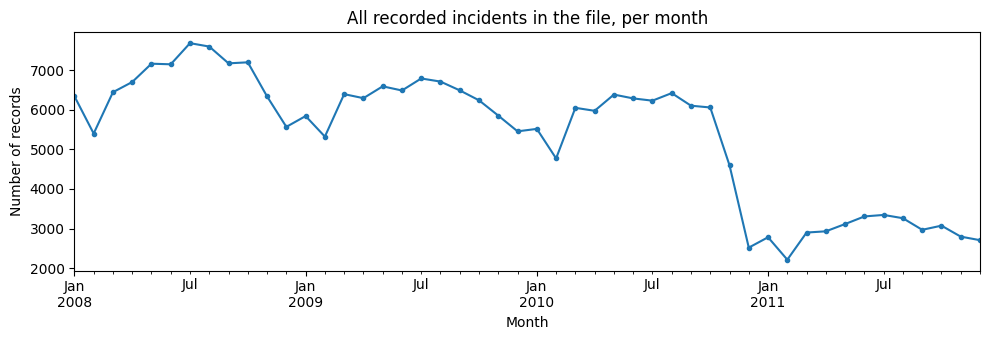

,n_records
Year,
2008,80757
2009,74469
2010,66908
2011,35378


In [16]:
monthly_all = df.groupby(df["Date"].dt.to_period("M")).size()

ax = monthly_all.plot(figsize=(10, 3.5), marker=".")
ax.set_title("All recorded incidents in the file, per month")
ax.set_xlabel("Month")
ax.set_ylabel("Number of records")
plt.tight_layout()
plt.show()

# dispay number of records per year
df.groupby("Year").size().to_frame("n_records")

The number of records drops suddenly at the end of 2010 and stays about half as high in 2011.
Crime does not fall by half overnight. Also, Chicago records several hundred thousand incidents per year, but this file has only about 81,000 for 2008.
So the file is most likely a **sample** (a part) of all records, and the sample became smaller after 2010.

**What this means for us:**
- Comparing counts **inside the same period** is fine (hours, weekdays, crime types, districts in 2008).
- Comparing raw counts **between years** is not fair. In Part 2 we use percentages per year instead.

### 4.1 At which hour are the most homicide incidents recorded?

In [17]:
homicide_by_hour = (
    df.loc[df["Primary.Type"] == "HOMICIDE", "hour"]
      .value_counts()
      .sort_index()
)
print("Total homicide records:", homicide_by_hour.sum())
print("Hour with the most homicide records:", homicide_by_hour.idxmax(),
      "h, with", homicide_by_hour.max(), "records")

# Homicide counts by hour
homicide_by_hour.sort_values(ascending=False).head().to_frame("n_homicides")

Total homicide records: 210
Hour with the most homicide records: 21 h, with 21 records


,n_homicides
hour,
21,21
0,18
2,16
18,12
22,12


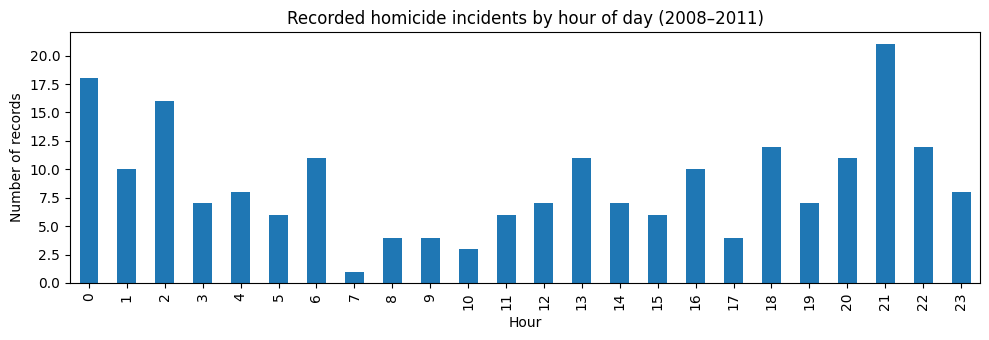

In [18]:
ax = homicide_by_hour.reindex(range(24), fill_value=0).plot.bar(figsize=(10, 3.5))
ax.set_title("Recorded homicide incidents by hour of day (2008–2011)")
ax.set_xlabel("Hour")
ax.set_ylabel("Number of records")
plt.tight_layout()
plt.show()

**Answer:** most homicide incidents are recorded at **21:00 (between 9 pm and 10 pm)**.
In general, homicides are recorded more in the evening and at night (about 18:00 to 03:00).
But there are only 210 homicide records in total, so small differences between hours (for example 21 at 21:00 and 18 at midnight) may just be chance.

### 4.2 Which weekday has the fewest recorded theft incidents?

In [19]:
theft_by_weekday = (
    df.loc[df["Primary.Type"] == "THEFT", "weekday"]
      .value_counts()
      .sort_index()
)
print("Weekday with the fewest theft records:", theft_by_weekday.idxmin(),
      f"({theft_by_weekday.min():,} records)")

#  Theft counts by weekday
theft_by_weekday.to_frame("n_thefts")

Weekday with the fewest theft records: Sunday (6,655 records)


,n_thefts
weekday,
Monday,7577
Tuesday,7968
Wednesday,7888
Thursday,7761
Friday,8259
Saturday,7557
Sunday,6655


**Answer:** **Sunday** has the fewest recorded thefts. Friday has the most. From Monday to Saturday the numbers are quite similar.

### 4.3 Which primary crime type is most frequent on 25 December?

In [20]:
is_christmas = (df["Date"].dt.month == 12) & (df["Date"].dt.day == 25) # combined condition on month and day

christmas_types = df.loc[is_christmas, "Primary.Type"].value_counts()
print("Records on 25 December (2008–2011 combined):", is_christmas.sum())
christmas_types.head().to_frame("n_records")

Records on 25 December (2008–2011 combined): 336


,n_records
Primary.Type,
BATTERY,84
CRIMINAL DAMAGE,47
THEFT,42
BURGLARY,29
NARCOTICS,24


In [21]:
# Same question, year by year, to check the answer is stable
christmas_by_year = (
    df[is_christmas]
      .groupby("Year")["Primary.Type"]
      .agg(lambda s: s.value_counts().idxmax())
      .to_frame("most_frequent_type")
)
christmas_by_year

,most_frequent_type
Year,
2008,BATTERY
2009,BATTERY
2010,BATTERY
2011,BATTERY


**Answer:** **BATTERY** is the most common crime type recorded on 25 December. Criminal damage and theft come next.
This is true for all years together and also for each year separately (see the table above).
In the full dataset, **THEFT** is the most common type. So on Christmas Day, battery is more common than usual.
One possible reason is that many people spend the day together at home, but our data cannot prove this.

## 5. Harmonizing location descriptions

`Location.Description` splits airports into many sub-categories (terminal levels, secure areas, parking...).
We merge them into one `"AIRPORT"` category in a **new** column `location_clean` and leave the original column unchanged.

In [22]:
is_airport = df["Location.Description"].str.contains("AIRPORT", na=False)   # na=False: missing values count as "no"

airport_values = df.loc[is_airport, "Location.Description"].value_counts()
print("Distinct location descriptions containing 'AIRPORT':", len(airport_values))
airport_values.to_frame("n_records")

Distinct location descriptions containing 'AIRPORT': 13


,n_records
Location.Description,
AIRPORT/AIRCRAFT,609
AIRPORT TERMINAL UPPER LEVEL - SECURE AREA,119
AIRPORT TERMINAL LOWER LEVEL - NON-SECURE AREA,52
AIRPORT EXTERIOR - NON-SECURE AREA,35
AIRPORT TERMINAL UPPER LEVEL - NON-SECURE AREA,28
AIRPORT TERMINAL LOWER LEVEL - SECURE AREA,27
AIRPORT BUILDING NON-TERMINAL - NON-SECURE AREA,23
AIRPORT PARKING LOT,13
AIRPORT BUILDING NON-TERMINAL - SECURE AREA,12


In [23]:
df["location_clean"] = df["Location.Description"].mask(is_airport, "AIRPORT")

print(f"Records affected (value replaced by 'AIRPORT'): {is_airport.sum():,}")
print("Distinct airport values — original column:", df.loc[is_airport, "Location.Description"].nunique(),
      "| cleaned column:", df.loc[is_airport, "location_clean"].nunique())

df.loc[is_airport, ["Location.Description", "location_clean"]].drop_duplicates().head()

Records affected (value replaced by 'AIRPORT'): 941
Distinct airport values — original column: 13 | cleaned column: 1


,Location.Description,location_clean
496,AIRPORT TERMINAL LOWER LEVEL - SECURE AREA,AIRPORT
503,AIRPORT/AIRCRAFT,AIRPORT
541,AIRPORT TERMINAL UPPER LEVEL - NON-SECURE AREA,AIRPORT
1509,AIRPORT EXTERIOR - NON-SECURE AREA,AIRPORT
1606,AIRPORT TERMINAL UPPER LEVEL - SECURE AREA,AIRPORT


There were 13 different airport descriptions. Now the 941 airport records all have the same value, `AIRPORT`, in `location_clean`.
This makes it easy to count airport incidents and compare them with other places.

## 6. Crime counts and population (2008)

We compute **recorded incidents per 1,000 residents** for each police district in 2008.

In [24]:
population = pd.DataFrame({
    "District": range(1, 26),
    "Name": ["Central", "Wentworth", "Grand Crossing", "South Chicago", "Calumet",
             "Gresham", "Englewood", "Chicago Lawn", "Deering", "Ogden",
             "Harrison", "Monroe", "Wood", "Shakespeare", "Austin",
             "Jefferson Park", "Albany Park", "Near North", "Belmont", "Lincoln",
             "Prairie", "Morgan Park", "Town Hall", "Rogers Park", "Grand Central"],
    "Population": [25613, 50957, 93384, 141422, 92729, 105360, 91600, 244470, 165457, 137120,
                   82392, 69677, 60517, 132459, 72736, 199898, 156859, 110995, 107516, 102512,
                   78111, 111545, 98391, 151435, 212535],
})
population.head()

,District,Name,Population
0,1,Central,25613
1,2,Wentworth,50957
2,3,Grand Crossing,93384
3,4,South Chicago,141422
4,5,Calumet,92729


In [25]:
counts_2008 = (
    df[df["Year"] == 2008]
      .groupby("District")
      .size()
      .rename("n_incidents")
      .reset_index()
)
counts_2008["District"] = counts_2008["District"].astype("int64") # same type as in `population`

# Outer merge with indicator=True so we can see districts that only appear in one table
check = population.merge(counts_2008, on="District", how="outer", indicator=True)
check[check["_merge"] != "both"]

,District,Name,Population,n_incidents,_merge
12,13,Wood,60517.0,NaN,left_only
20,21,Prairie,78111.0,NaN,left_only
22,23,Town Hall,98391.0,NaN,left_only
25,31,NaN,NaN,3.0,right_only


The merge shows two problems:

- **Districts 13 (Wood), 21 (Prairie) and 23 (Town Hall) have no records.** Chicago closed these districts in 2012–2013. The data seems to use the new district map, so their incidents are counted in the neighbouring districts.
  Their rate would be 0, which makes no sense, so we leave them out.
- **District 31** has a few records but no population in the table, so we cannot compute a rate for it.

So we keep only the districts that are in both tables (an inner merge).

In [26]:
rates = population.merge(counts_2008, on="District", how="inner")
rates["incidents_per_1000"] = rates["n_incidents"] / rates["Population"] * 1000
rates = rates.sort_values("incidents_per_1000", ascending=False).reset_index(drop=True)

rates.round({"incidents_per_1000": 1})

,District,Name,Population,n_incidents,incidents_per_1000
0,1,Central,25613,2985,116.5
1,2,Wentworth,50957,3404,66.8
2,11,Harrison,82392,4874,59.2
3,12,Monroe,69677,3960,56.8
4,7,Englewood,91600,5156,56.3
5,15,Austin,72736,3630,49.9
6,6,Gresham,105360,4938,46.9
7,3,Grand Crossing,93384,3996,42.8
8,5,Calumet,92729,3654,39.4
9,4,South Chicago,141422,4694,33.2


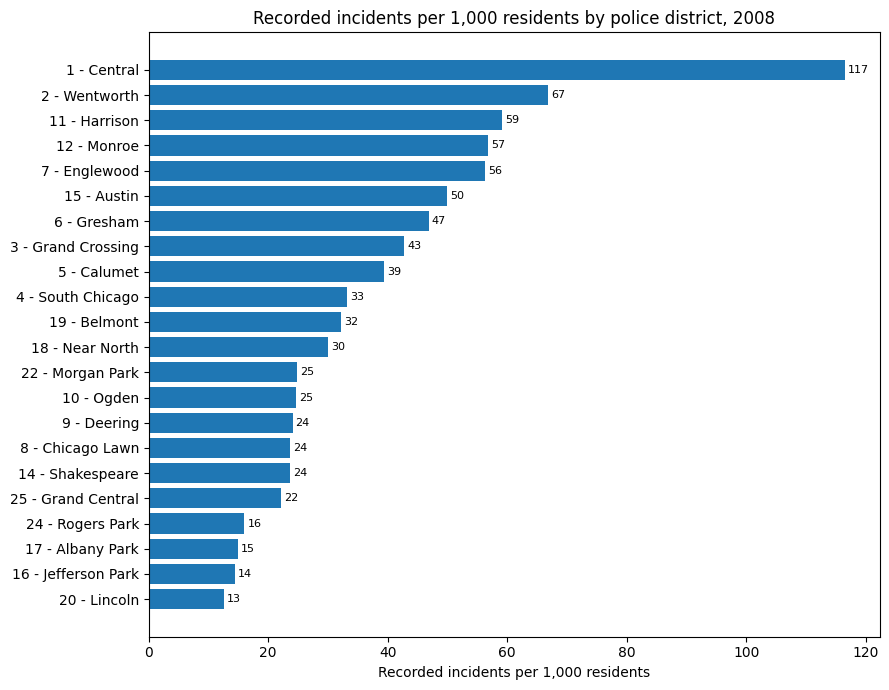

In [27]:
labels = rates["District"].astype(str) + " - " + rates["Name"]
incidents_per_1000 = rates["incidents_per_1000"]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(labels, incidents_per_1000)
ax.invert_yaxis() # highest value at the top
ax.set_xlabel("Recorded incidents per 1,000 residents")
ax.set_title("Recorded incidents per 1,000 residents by police district, 2008")
for i, v in enumerate(incidents_per_1000):
    ax.text(v + 0.5, i, f"{v:.0f}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

**Interpretation**

- **District 1 (Central)** has by far the highest rate: more than 100 recorded incidents per 1,000 residents.
  This does **not** mean that people living downtown are most at risk. Few people live there, but many people come every day to work, shop or visit. Their incidents are counted, but they are not in the population. This makes the rate look very high.
- Next come some South and West Side districts: Wentworth (2), Harrison (11), Monroe (12), Englewood (7) and Austin (15), with about 50–67 recorded incidents per 1,000 residents.
- North Side districts (Lincoln, Jefferson Park, Albany Park, Rogers Park) have the lowest rates, about 13–16 per 1,000. That is 4 to 5 times lower than the group above.

**Be careful:**

1. This number compares *recorded incidents* with *residents*. It is not the chance that one person becomes a victim.
2. The file seems to be a sample, so the real numbers are higher. Only the **order** of the districts is useful.
3. Some neighbouring districts also include incidents from the closed districts 13, 21 and 23, but we divide by their old population. So their rate is too high. Monroe (12) is probably one example.

## 7. Arrest proportion by crime type

`Arrest` is boolean (True/False), so its **mean** is the proportion of incidents with an arrest.

In [28]:
arrests = (
    df.groupby("Primary.Type")
      .agg(n_incidents=("ID", "size"),
           arrest_prop=("Arrest", "mean"))
)
arrests = arrests[arrests["n_incidents"] >= 100].sort_values("arrest_prop")

print(f"{len(arrests)} crime types with at least 100 recorded incidents")
arrests.round({"arrest_prop": 3})

25 crime types with at least 100 recorded incidents


,n_incidents,arrest_prop
Primary.Type,,
BURGLARY,17406,0.053
MOTOR VEHICLE THEFT,12128,0.068
CRIMINAL DAMAGE,30002,0.069
KIDNAPPING,194,0.093
ROBBERY,10240,0.095
THEFT,53665,0.110
ARSON,352,0.114
OTHER OFFENSE,15962,0.150
CRIM SEXUAL ASSAULT,961,0.153


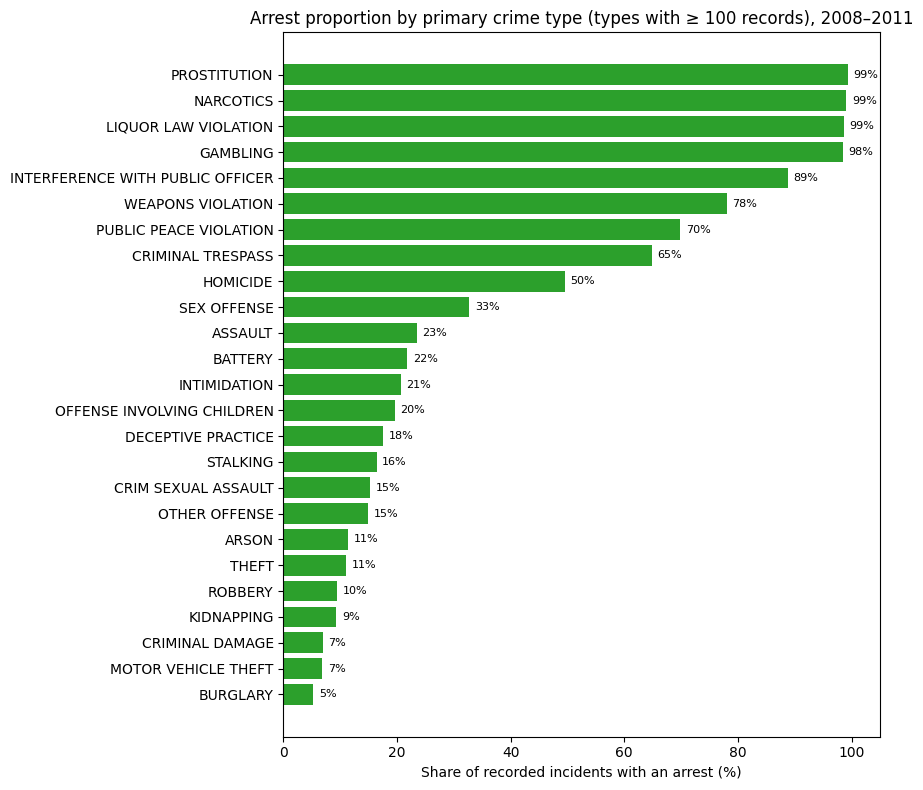

In [29]:
fig, ax = plt.subplots(figsize=(9, 8))
arrest_prop = arrests["arrest_prop"] * 100

ax.barh(arrests.index, arrest_prop, color="tab:green")
ax.set_xlabel("Share of recorded incidents with an arrest (%)")
ax.set_title("Arrest proportion by primary crime type (types with ≥ 100 records), 2008–2011")
ax.set_xlim(0, 105)
for i, v in enumerate(arrest_prop):
    ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=8)
plt.tight_layout()
plt.show()

**Interpretation**

The crime types fall into two clear groups:

- **More than 60% with an arrest:** narcotics, prostitution, liquor law violations, gambling, interference with a public officer, weapons violations, public peace violation, criminal trespass.
  The police usually **find these crimes themselves** (during patrols or stops), so the arrest often happens at the same time the incident is recorded.
- **Less than 25% with an arrest:** most other types, for example burglary (about 5%), motor vehicle theft, criminal damage, robbery, theft, battery and assault.
  These are usually **reported by the victim later**, when the offender is already gone and unknown.

Homicide is in the middle, at about 50%.
Note: these numbers only show arrests written in this dataset. Some arrests may have happened later and were not added to the record.

# Part 2 - Open exploratory analysis: **BURGLARY**

**Selected crime type: `BURGLARY`** (entering a building illegally to commit a crime, for example to steal).

Why we chose it:
- it is common (about 17,000 records), so the patterns are reliable;
- it has the **lowest arrest rate** of all common crime types (Section 7);
- when and where it happens tells us when homes and shops are left empty.

We look at four questions:

1. **When in the year?** Monthly counts and seasons
2. **When in the day and week?** Hour × weekday
3. **What and where?** Types of burglary, types of places, and arrests
4. **Where in the city?** Map

In [30]:
burglary = df[df["Primary.Type"] == "BURGLARY"].copy()
print(f"Burglary records: {len(burglary):,}  ({len(burglary) / len(df):.1%} of all records)")

burglary.head()

Burglary records: 17,406  (6.8% of all records)


,Unnamed: 0,ID,Case.Number,Date,Block,IUCR,Primary.Type,Description,Location.Description,Arrest,...,Year,Updated.On,Latitude,Longitude,Location,calendar_date,hour,weekday,month,location_clean
1,238567,6380338,HP465037,2008-07-21 23:30:00,043XX S ROCKWELL ST,0610,BURGLARY,FORCIBLE ENTRY,APARTMENT,False,...,2008,02/04/2016 06:33:39 AM,41.814888,-87.689507,"(41.814887983, -87.689506618)",2008-07-21,23,Monday,7,APARTMENT
13,320706,6516142,HP590063,2008-09-20 22:00:00,033XX N AVERS AVE,0610,BURGLARY,FORCIBLE ENTRY,RESIDENCE-GARAGE,False,...,2008,02/04/2016 06:33:39 AM,41.941510,-87.723590,"(41.941509768, -87.723590139)",2008-09-20,22,Saturday,9,RESIDENCE-GARAGE
27,2683160,8499209,HV176044,2011-05-31 10:00:00,033XX W FULTON BLVD,0610,BURGLARY,FORCIBLE ENTRY,APARTMENT,False,...,2011,02/04/2016 06:33:39 AM,41.886370,-87.709774,"(41.886369807, -87.709773808)",2011-05-31,10,Tuesday,5,APARTMENT
43,2004757,7365529,HS168439,2010-02-16 12:00:00,015XX S KOLIN AVE,0610,BURGLARY,FORCIBLE ENTRY,RESIDENCE-GARAGE,False,...,2010,02/04/2016 06:33:39 AM,41.859781,-87.733545,"(41.859781121, -87.733544509)",2010-02-16,12,Tuesday,2,RESIDENCE-GARAGE
68,2324589,7863014,HS677672,2010-12-22 09:00:00,011XX N LECLAIRE AVE,0610,BURGLARY,FORCIBLE ENTRY,APARTMENT,False,...,2010,02/04/2016 06:33:39 AM,41.900901,-87.753293,"(41.900900864, -87.753293142)",2010-12-22,9,Wednesday,12,APARTMENT


## 8.1 When in the year? Monthly counts and seasons

**Question:** does the number of recorded burglaries change with the seasons?

Section 4 showed that the file has fewer records after 2010, so we cannot compare raw counts between years.
Instead, for each year we compute the **percentage of that year's burglaries** that happened in each month. This way all years can be compared.

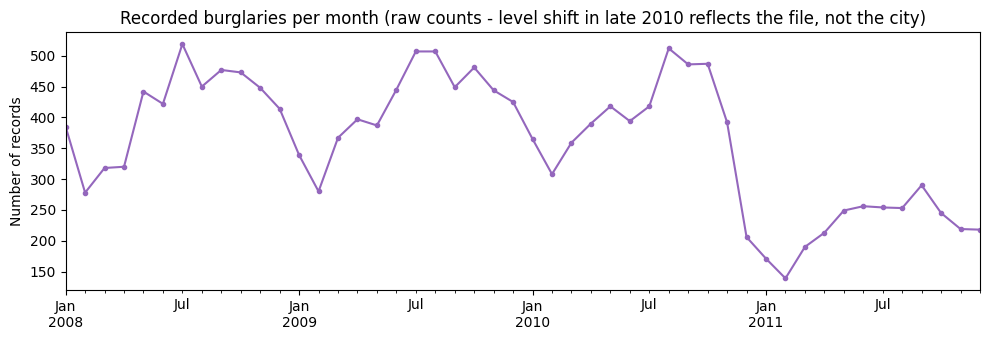

In [31]:
monthly_burglary = burglary.groupby(burglary["Date"].dt.to_period("M")).size()

fig, ax = plt.subplots(figsize=(10, 3.5))
monthly_burglary.plot(ax=ax, marker=".", color="tab:purple")
ax.set_title("Recorded burglaries per month (raw counts - level shift in late 2010 reflects the file, not the city)")
ax.set_xlabel("")
ax.set_ylabel("Number of records")
plt.tight_layout()
plt.show()

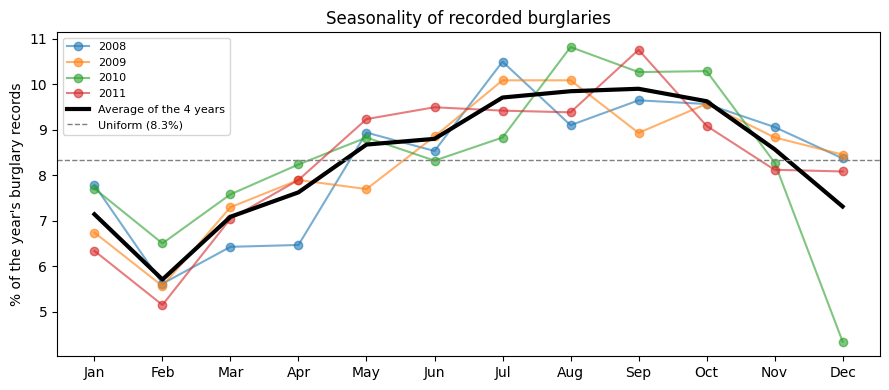

Year,2008,2009,2010,2011
month,,,,
1,7.8,6.7,7.7,6.3
2,5.6,5.6,6.5,5.2
3,6.4,7.3,7.6,7.0
4,6.5,7.9,8.2,7.9
5,8.9,7.7,8.8,9.2
6,8.5,8.9,8.3,9.5
7,10.5,10.1,8.8,9.4
8,9.1,10.1,10.8,9.4
9,9.6,8.9,10.3,10.8


In [32]:
# Share of each year's burglaries falling in each month
month_year = pd.crosstab(burglary["month"], burglary["Year"], normalize="columns") * 100
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(9, 4))
month_year.plot(ax=ax, marker="o", alpha=0.6)
month_year.mean(axis=1).plot(ax=ax, color="black", linewidth=3, label="Average of the 4 years")
ax.axhline(100 / 12, color="grey", linestyle="--", linewidth=1, label="Uniform (8.3%)")
ax.set_xticks(range(1, len(months) + 1))
ax.set_xticklabels(months)
ax.set_xlabel("")
ax.set_ylabel("% of the year's burglary records")
ax.set_title("Seasonality of recorded burglaries")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

month_year.round(1)

**Interpretation:** recorded burglaries follow the **seasons**. The percentage goes up from late winter and stays high from **July to October** (about 10% of the year's records each month). It goes down again in winter. February is the lowest month, partly because it has fewer days.
December 2010 is very low (4.4%), but this is because of the smaller sample (Section 4), not a real drop.
All four years have the same shape, so this pattern is reliable.
A possible reason: in summer people travel more and leave windows open. But our data cannot prove this.

## 8.2 When in the day and week? Hour × weekday

**Question:** at what time of day are burglaries recorded? Is it the same on weekdays and at the weekend?

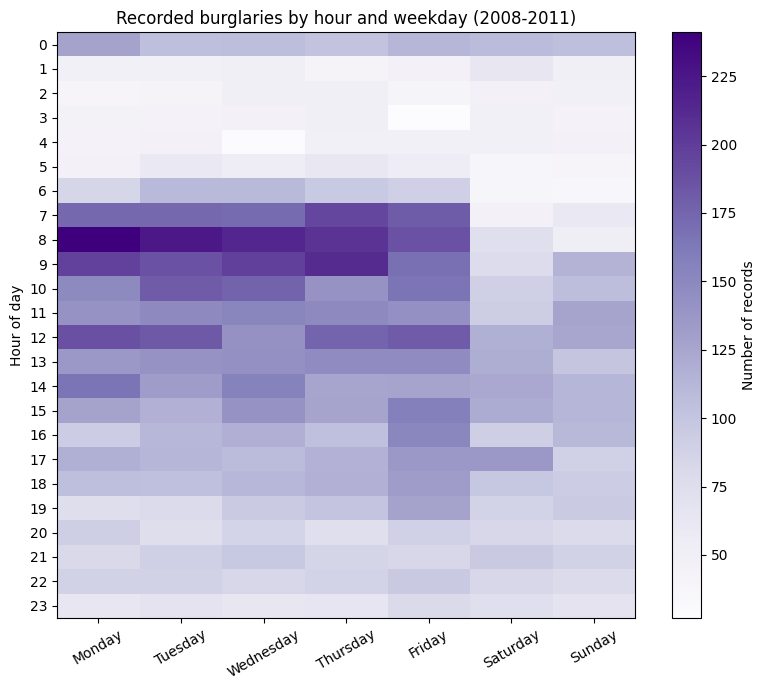

In [33]:
hour_weekday = pd.crosstab(burglary["hour"], burglary["weekday"])

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(hour_weekday, aspect="auto", cmap="Purples")
ax.set_xticks(range(7))
ax.set_xticklabels(hour_weekday.columns, rotation=30)
ax.set_yticks(range(24))
ax.set_ylabel("Hour of day")
ax.set_title("Recorded burglaries by hour and weekday (2008-2011)")
fig.colorbar(im, ax=ax, label="Number of records")
plt.tight_layout()
plt.show()

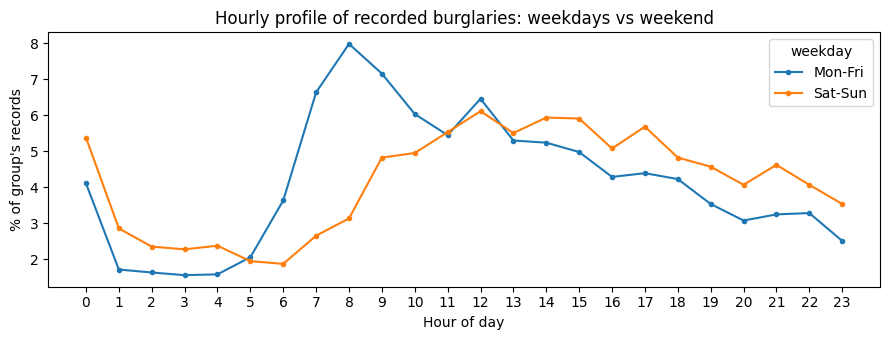

,n_burglaries
weekday,
Monday,2663
Tuesday,2660
Wednesday,2694
Thursday,2662
Friday,2766
Saturday,1993
Sunday,1968


In [34]:
# Hourly profile, weekdays vs weekend, as % of each group so the two lines are comparable
is_weekend = burglary["weekday"].isin(["Saturday", "Sunday"])
hour_profile = pd.crosstab(burglary["hour"], is_weekend.map({False: "Mon-Fri", True: "Sat-Sun"}),
                           normalize="columns") * 100

ax = hour_profile.plot(figsize=(9, 3.5), marker=".")
ax.set_xticks(range(0, 24))
ax.set_xlabel("Hour of day")
ax.set_ylabel("% of group's records")
ax.set_title("Hourly profile of recorded burglaries: weekdays vs weekend")
plt.tight_layout()
plt.show()

burglary["weekday"].value_counts().sort_index().to_frame("n_burglaries")

**Interpretation**

- Most burglaries are recorded **during the day on weekdays**. The number goes up quickly from 07:00 and stays high until the afternoon (highest between 08:00 and 12:00).
  This makes sense: homes are often empty while people are at work or school.
- **Saturday and Sunday** have about 25% fewer records than weekdays, and there is no strong morning peak. When more people are at home, fewer burglaries are recorded.
- There is a **jump at midnight (00:00)**. This is probably not real. When victims do not know the exact time (for example, they come home after a trip), the time is often written as 00:00.
  So `hour` is the *recorded* time, not always the real time.

## 8.3 What and where? Types of burglary, places and arrests

**Questions:** what kinds of burglary are recorded? In what kinds of places? Is the arrest rate different for each kind?
We use the cleaned location column from Section 5.

In [35]:
by_description = (
    burglary.groupby("Description")
            .agg(n=("ID", "size"), arrest_prop=("Arrest", "mean"))
            .sort_values("n", ascending=False)
)
by_description["share"] = by_description["n"] / by_description["n"].sum()
by_description.round({"arrest_prop": 3, "share": 3})

,n,arrest_prop,share
Description,,,
FORCIBLE ENTRY,11862,0.051,0.681
UNLAWFUL ENTRY,4536,0.045,0.261
ATTEMPT FORCIBLE ENTRY,780,0.105,0.045
HOME INVASION,228,0.127,0.013


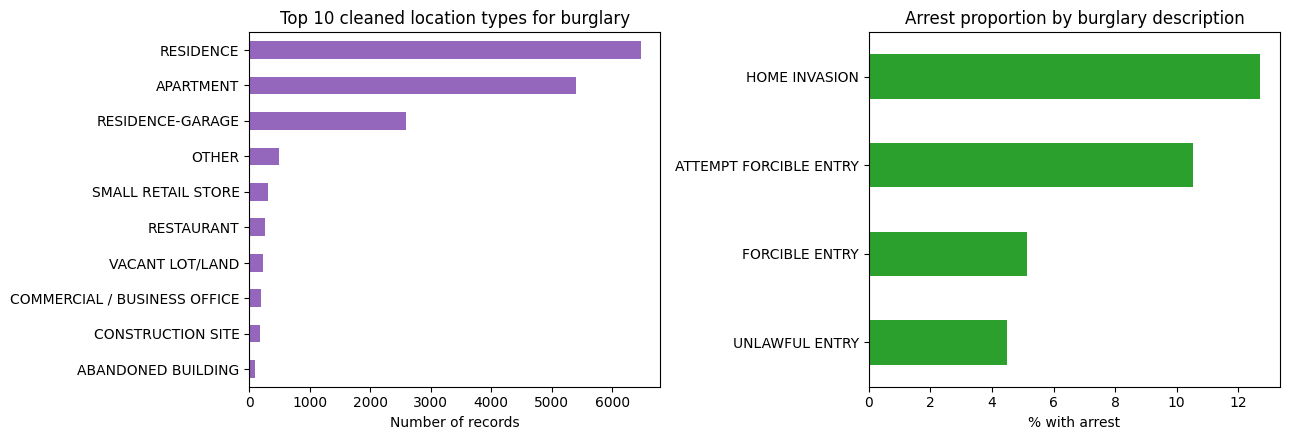

,% of burglaries
location_clean,
RESIDENCE,37.2
APARTMENT,31.1
RESIDENCE-GARAGE,14.9
OTHER,2.8
SMALL RETAIL STORE,1.7
RESTAURANT,1.5
VACANT LOT/LAND,1.3
COMMERCIAL / BUSINESS OFFICE,1.1
CONSTRUCTION SITE,1.0


In [36]:
top_locations = burglary["location_clean"].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

top_locations.sort_values().plot.barh(ax=axes[0], color="tab:purple")
axes[0].set_title("Top 10 cleaned location types for burglary")
axes[0].set_xlabel("Number of records")
axes[0].set_ylabel("")

(by_description["arrest_prop"] * 100).sort_values().plot.barh(ax=axes[1], color="tab:green")
axes[1].set_title("Arrest proportion by burglary description")
axes[1].set_xlabel("% with arrest")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

(top_locations / len(burglary) * 100).round(1).to_frame("% of burglaries")

**Interpretation**

- About two thirds of burglaries are **forcible entry** (the door or window is broken). About one quarter are **unlawful entry** (no force, for example through an open door).
- Burglary happens mostly in **homes**. Houses, apartments and home garages together make more than 80% of the records. Shops, restaurants and offices are only a small part.
- The arrest rate is low for every type. But for **home invasion** (people are at home, about 13%) and **attempted forcible entry** (about 10%), it is about twice as high as for completed burglaries (about 5%).
  This makes sense: the offender may be stopped or seen during the crime. A completed burglary is usually found later, when the offender is gone. (Home invasion has only about 230 records, so this result is less certain.)

## 8.4 Where in the city? Map

**Question:** are recorded burglaries spread evenly over the city, or are some areas more affected?
Records without coordinates (about 1%) or with wrong coordinates are left out, but only for this map.

In [37]:
# A few records have coordinates far outside Chicago (all at one identical point in Missouri,  most likely a default value). We keep only coordinates inside a generous box around the city.
has_coords = df["Latitude"].notna() & df["Longitude"].notna()
in_chicago = df["Latitude"].between(41.6, 42.1) & df["Longitude"].between(-88.0, -87.5)

print("Records with coordinates outside Chicago:", (has_coords & ~in_chicago).sum())
df.loc[has_coords & ~in_chicago, ["Latitude", "Longitude"]].value_counts().to_frame("n_records")

Records with coordinates outside Chicago: 19


,,n_records
Latitude,Longitude,
36.619446,-91.686566,19


Burglary records with valid coordinates: 17,301 / 17,406


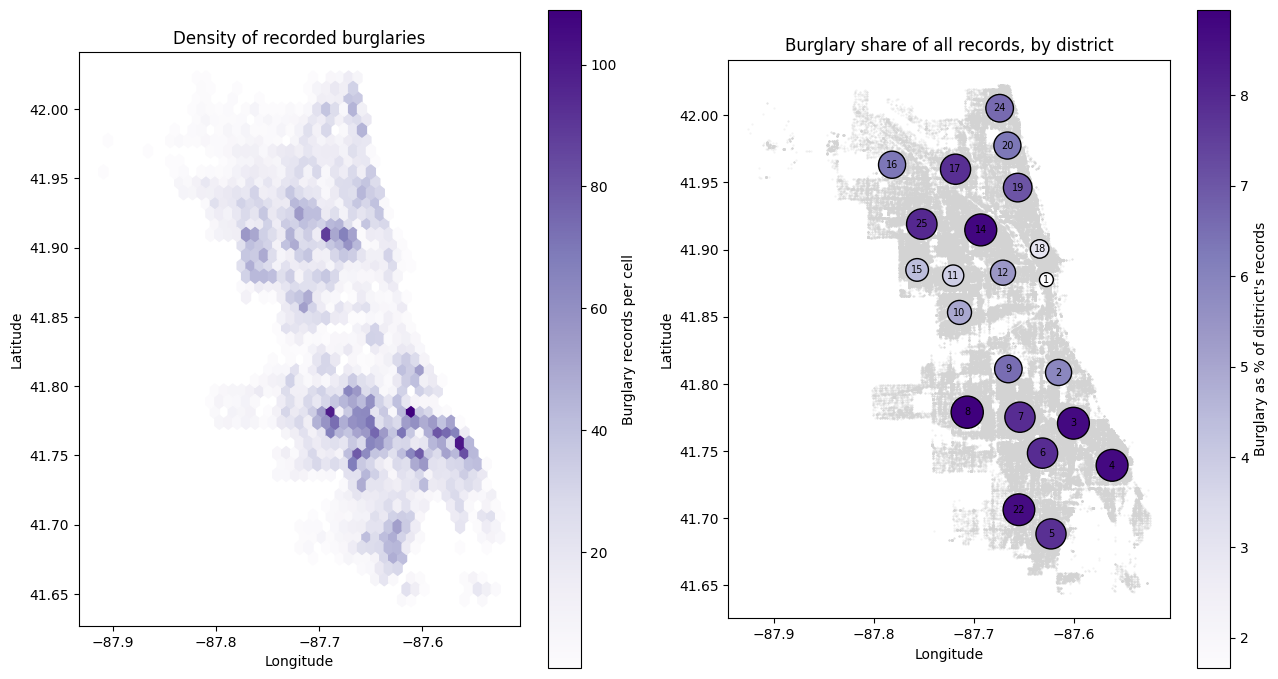

,Burglary % of records
District,
8,8.9
14,8.8
3,8.7
4,8.7
22,8.7
10,5.0
15,4.4
11,3.9
18,3.0


In [38]:
geo = burglary[in_chicago.loc[burglary.index]] # only burglary records with valid coordinates
city = df[in_chicago] # only records with valid coordinates
print(f"Burglary records with valid coordinates: {len(geo):,} / {len(burglary):,}")

fig, axes = plt.subplots(1, 2, figsize=(13, 7))

# Left: density of burglary records
hb = axes[0].hexbin(geo["Longitude"], geo["Latitude"], gridsize=45, cmap="Purples", mincnt=1)
fig.colorbar(hb, ax=axes[0], label="Burglary records per cell")
axes[0].set_title("Density of recorded burglaries")

# Right: burglary's share of all records in each police district
# mean of a True/False column = proportion of True; rows without a district are skipped by groupby
district_share = (df["Primary.Type"] == "BURGLARY").groupby(df["District"]).mean() * 100
centroids = city.dropna(subset=["District"]).groupby("District")[["Longitude", "Latitude"]].median()
centroids = centroids.join(district_share.rename("burglary_pct"))
centroids = centroids[df.groupby("District").size().reindex(centroids.index) > 100]   # drop tiny district 31

axes[1].scatter(city["Longitude"], city["Latitude"], s=0.2, color="lightgrey", alpha=0.3)
sc = axes[1].scatter(centroids["Longitude"], centroids["Latitude"], s=centroids["burglary_pct"] * 60,
                     c=centroids["burglary_pct"], cmap="Purples", edgecolor="black")
for d, row in centroids.iterrows():
    axes[1].annotate(str(d), (row["Longitude"], row["Latitude"]), ha="center", va="center", fontsize=7)
fig.colorbar(sc, ax=axes[1], label="Burglary as % of district's records")
axes[1].set_title("Burglary share of all records, by district")

for ax in axes:
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_aspect(1 / np.cos(np.radians(41.85)))   # approximately correct shape at Chicago's latitude
    ax.locator_params(axis="x", nbins=5)
plt.tight_layout()
plt.show()

shares = centroids["burglary_pct"].sort_values(ascending=False).round(1)
pd.concat([shares.head(), shares.tail()]).to_frame("Burglary % of records")   # 5 highest and 5 lowest

**Interpretation**

- **Left map:** burglaries are recorded almost everywhere in the city (you can see the shape of Chicago).
  There are the most on the **South Side** (latitude about 41.74–41.79) and in one area on the **north-west side** (latitude about 41.91).
  Downtown near the lake and the far north-west have few burglaries.
- **Right map:** this shows burglary as a **percentage of all crimes** in each district. It tells us how important burglary is compared to other crimes there.
  Burglary is most important in the **South Side** districts where many people live (3, 4, 6, 7, 8, 22) and in north-west district 14 (Shakespeare): about 8–9% of records.
  It is least important in **District 1 (Central)** and **District 18 (Near North)**, where shop thefts are more common, and in West Side districts 10, 11 and 15, where there are many narcotics records.
- Together, the two maps show that burglary depends a lot on **what the area is used for**: it is more common in areas with homes than in business areas. This matches the results in 8.3.

## Conclusion

**Data preparation**

- 11,358 duplicate records (same `ID`, same content) were removed, so there is one record per ID.
- One broken row (values moved to the wrong columns, invalid `ID`) was found and removed. Then `ID`, `Arrest`, `Domestic`, `Year`, `District`, `Ward` and `Community.Area` were given the correct types.
- `Date` was converted to a date, and we created `calendar_date`, `hour`, `weekday` and `month` from it.
- A few records with wrong coordinates (outside Chicago) were left out of the map.
- All airport location descriptions were grouped into one value, `AIRPORT`, in a new column `location_clean`.
- The file seems to be a sample, with fewer records after 2010. So we compared counts only inside the same period, or used percentages.

**Answers to the core questions**

| Question | Answer |
|---|---|
| Hour with the most homicide records | 21:00 (only 210 homicides in total, so be careful) |
| Weekday with the fewest theft records | Sunday |
| Most common crime type on 25 December | BATTERY |
| Highest recorded incidents per 1,000 residents (2008) | District 1 – Central (because few people live there) |
| Lowest arrest rate (types with ≥ 100 records) | BURGLARY (about 5%); highest: PROSTITUTION / NARCOTICS (about 99%) |

**Burglary:** it happens mostly in homes, during the day, on weekdays, and more in summer and early autumn. It has the lowest arrest rate of all common crime types.
All results describe **recorded incidents in this dataset**, not the real amount of crime.